# The Saudi Water Paradox: Flood Susceptibility Prediction in Jeddah
### Final project notebook

This notebook contains the full workflow, from loading the data to the final model:

- **Part 1 - Exploratory Data Analysis (sections 1-8):** data loading, quality checks, cleaning, exploratory analysis and preprocessing.
- **Part 2 - Machine Learning (sections 9-21):** problem definition, validation design, model training and comparison, evaluation, interpretation and the final model.

The raw files `jeddah_flood_ml.csv` and `jeddah_flood_ml_elev_matched.csv` should be in `data/raw/`. The whole notebook takes about 8-10 minutes to run.

---

# Exploratory Data Analysis: Jeddah Flood Dataset
**The Saudi Water Paradox: Flood Susceptibility Prediction Using Multi-Source Geospatial Data**

In this notebook we explore the Jeddah flood dataset (two flood events: 21 Nov 2017 and 24 Nov 2022), clean it, and prepare it for modeling.

**Steps:** load data, quality checks, cleaning, exploratory analysis, outliers, preprocessing export, summary of findings.

## 1. Setup

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')

# Folders (works from the project root or from the notebooks folder)
ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
FIG, OUT, PROC = ROOT / 'outputs/figures', ROOT / 'outputs', ROOT / 'data/processed'
for folder in [FIG, OUT, PROC, ROOT / 'src', ROOT / 'docs']:
    folder.mkdir(parents=True, exist_ok=True)

# Water-themed colors: blue = flooded, sand = dry
BLUE, SAND, NAVY, AQUA = '#0077B6', '#E9C46A', '#03045E', '#48CAE4'
LABEL_COLORS = {0: SAND, 1: BLUE}
water_cmap = LinearSegmentedColormap.from_list('water', ['#F6E7B4', '#90E0EF', '#0077B6', '#03045E'])
div_cmap = LinearSegmentedColormap.from_list('div', ['#C9953C', '#FFFFFF', '#0077B6'])

sns.set_theme(style='whitegrid', rc={'axes.titlesize': 11, 'axes.titleweight': 'normal', 'figure.dpi': 100})

SOURCE = 'Source: Copernicus GFM and DEM GLO-30, ESA WorldCover 2021, NASA GPM IMERG V07, NASA SMAP L4'

def save(fig, name, title):
    # adds a title and the data source, then saves the figure
    fig.suptitle(title, fontsize=12)
    fig.text(0.99, 0.0, SOURCE, ha='right', fontsize=7, color='gray')
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=200, bbox_inches='tight')
    plt.show()

## 2. Load the data

In [2]:
FILES = {'main': 'jeddah_flood_ml.csv', 'matched': 'jeddah_flood_ml_elev_matched.csv'}

def find(name):
    for p in [Path(name), ROOT / 'data/raw' / name, Path('/content') / name]:
        if p.exists():
            return p

if any(find(f) is None for f in FILES.values()):   # on Colab: upload the two CSV files
    from google.colab import files
    files.upload()

raw = {key: pd.read_csv(find(f)) for key, f in FILES.items()}
for key, d in raw.items():
    print(key, d.shape)

main (40054, 35)
matched (35844, 35)


There are two files with the same columns:
- **main**: all sampled cells (40,054 rows).
- **matched**: same flooded cells, but the dry cells were chosen to have elevations similar to the flooded ones (35,844 rows). This is a harder and fairer test, because elevation alone cannot separate the classes as easily.

Each row is a 30 m x 30 m cell in one event. `label = 1` means new flood water was detected by Sentinel-1 after the event. `label = 0` means no water was seen, which does **not** mean the place is safe.

## 3. Data quality

In [3]:
# Basic sanity checks on both files
for key, d in raw.items():
    print(key)
    print('  duplicate (cell_id, event_id):', d.duplicated(['cell_id', 'event_id']).sum())
    print('  labels:', sorted(d.label.unique()))
    print('  slope in [0, 90]:', d.slope_deg.dropna().between(0, 90).all())
    print('  distances >= 0:', (d[['dist_to_coast_m', 'dist_to_ref_water_m']] >= 0).all().all())
    print('  soil moisture in [0, 1]:', d[['sm_surface_m3m3', 'sm_rootzone_m3m3']].apply(lambda s: s.between(0, 1).all()).all())
    print('  rainfall >= 0:', (d.filter(like='rain_') >= 0).all().all())

main
  duplicate (cell_id, event_id): 0
  labels: [np.int64(0), np.int64(1)]
  slope in [0, 90]: True
  distances >= 0: True
  soil moisture in [0, 1]: True
  rainfall >= 0: True
matched
  duplicate (cell_id, event_id): 0
  labels: [np.int64(0), np.int64(1)]
  slope in [0, 90]: True
  distances >= 0: True
  soil moisture in [0, 1]: True
  rainfall >= 0: True


In [4]:
# Missing values, and how they differ between flooded and dry cells
rows = []
for key, d in raw.items():
    for col in d.columns[d.isna().any()]:
        rows.append({'file': key, 'column': col, 'missing': d[col].isna().sum(),
                     'pct': round(100 * d[col].isna().mean(), 2),
                     'pct_flooded': round(100 * d.loc[d.label == 1, col].isna().mean(), 2),
                     'pct_dry': round(100 * d.loc[d.label == 0, col].isna().mean(), 2)})
missing = pd.DataFrame(rows)
missing.to_csv(OUT / 'missing_summary.csv', index=False)
print(missing.to_string(index=False))

   file             column  missing   pct  pct_flooded  pct_dry
   main          slope_deg       55  0.14         0.10     0.17
   main                twi       55  0.14         0.10     0.17
   main             hand_m      738  1.84         2.44     1.24
   main    hand_ref_is_sea      738  1.84         2.44     1.24
   main s2_water_confirmed     8179 20.42        25.05    15.79
matched          slope_deg      473  1.32         0.10     2.86
matched                twi      473  1.32         0.10     2.86
matched             hand_m     1034  2.88         2.44     3.45
matched    hand_ref_is_sea     1034  2.88         2.44     3.45
matched s2_water_confirmed     9922 27.68        25.05    31.01


Only `slope_deg`, `twi` and `hand_m` have missing values (and `s2_water_confirmed`, which is a label-quality column that is not used as a feature). They are few, so we keep all rows and impute them later inside the modeling pipeline using training data only.

In the matched file, `slope_deg` and `twi` are missing much more often for dry cells than for flooded cells. So we will **not** create "is missing" features, because they would leak information about the label.

## 4. Cleaning
- Drop the columns that must not be used in a model (label metadata and flags, as listed in the data dictionary).
- Add `block_5km` and `block_10km` from the coordinates, for spatial splitting.
- Group the rare land cover classes into 4 groups.
- Add log versions of the very skewed columns (useful for Logistic Regression).
- No rows are removed and no values are clipped (see the outliers section).

In [5]:
DROP = ['s2_water_confirmed', 'flood_fraction', 'label_obs_utc', 'label_source', 'hand_ref_is_sea',
        'sm_filled_from_neighbor', 'sampling_stratum', 'imerg_run', 'gfm_version', 'landcover_year_gap', 't0_utc']

LANDCOVER_GROUP = {'bare_sparse': 'bare_sparse', 'built_up': 'built_up',
                   'tree_cover': 'vegetation', 'shrubland': 'vegetation', 'grassland': 'vegetation', 'cropland': 'vegetation',
                   'permanent_water': 'water_wetland', 'herbaceous_wetland': 'water_wetland', 'mangroves': 'water_wetland'}

def clean(df):
    df = df.drop(columns=DROP).copy()
    df['year'] = df.event_id.str.extract(r'JED_(\d{4})')[0].astype(int)
    df['block_5km'] = (df.x // 5000).astype(int).astype(str) + '_' + (df.y // 5000).astype(int).astype(str)
    df['block_10km'] = (df.x // 10000).astype(int).astype(str) + '_' + (df.y // 10000).astype(int).astype(str)
    df['landcover_group'] = df.landcover_name.map(LANDCOVER_GROUP)
    df['flowacc_log10'] = np.log10(df.flowacc_km2.clip(lower=0.0009))   # 0.0009 km2 = one 30 m cell
    df['hand_log1p'] = np.log1p(df.hand_m)
    df['dist_coast_log1p'] = np.log1p(df.dist_to_coast_m)
    df['dist_refwater_log1p'] = np.log1p(df.dist_to_ref_water_m)
    return df

main, matched = clean(raw['main']), clean(raw['matched'])
print(main.shape, matched.shape)

(40054, 32) (35844, 32)


## 5. Exploratory analysis

### 5.1 Class balance

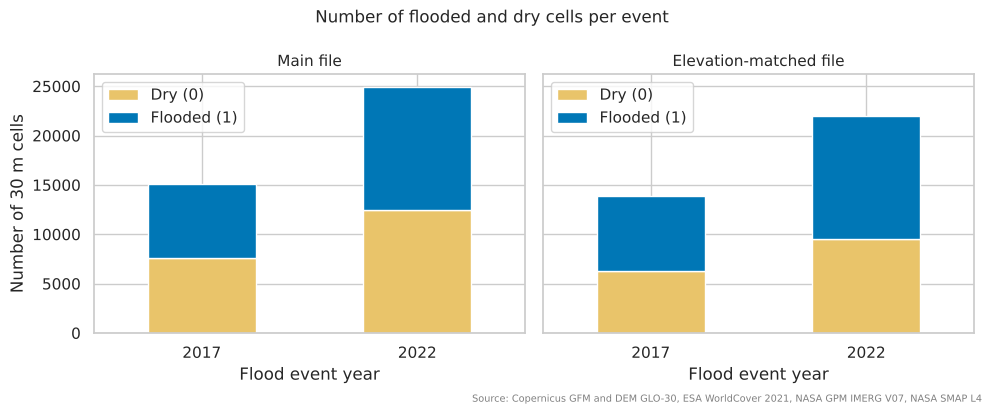

year
2017    0.5
2022    0.5
Name: label, dtype: float64
year
2017    0.545
2022    0.567
Name: label, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, d) in zip(axes, [('Main file', main), ('Elevation-matched file', matched)]):
    counts = d.groupby(['year', 'label']).size().unstack()
    counts.plot.bar(stacked=True, ax=ax, color=[SAND, BLUE], rot=0)
    ax.set_title(name)
    ax.set_xlabel('Flood event year')
    ax.set_ylabel('Number of 30 m cells')
    ax.legend(['Dry (0)', 'Flooded (1)'])
save(fig, '01_class_balance.png', 'Number of flooded and dry cells per event')
print(main.groupby('year').label.mean().round(3))
print(matched.groupby('year').label.mean().round(3))

**Observation:** the main file is exactly 50% flooded and the matched file is about 54-57% flooded. This comes from how the cells were sampled, it is **not** the real share of flooded land in Jeddah (which is much smaller). So precision and PR-AUC on this data will not reflect real-world performance, and ROC-AUC is a safer metric to compare models. Because the classes are already close to balanced, resampling methods such as SMOTE are not needed.

### 5.2 Elevation

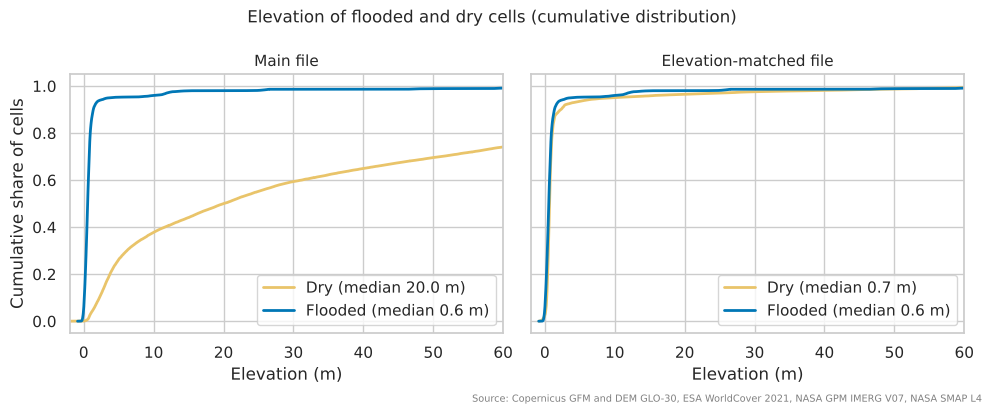

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, d) in zip(axes, [('Main file', main), ('Elevation-matched file', matched)]):
    for label, color, text in [(0, SAND, 'Dry'), (1, BLUE, 'Flooded')]:
        values = np.sort(d.loc[d.label == label, 'elevation_m'].values)
        ax.plot(values, np.arange(1, len(values) + 1) / len(values), color=color, lw=2,
                label=f'{text} (median {np.median(values):.1f} m)')
    ax.set_xlim(-2, 60)
    ax.set_title(name)
    ax.set_xlabel('Elevation (m)')
    ax.legend(loc='lower right')
axes[0].set_ylabel('Cumulative share of cells')
save(fig, '02_elevation_ecdf.png', 'Elevation of flooded and dry cells (cumulative distribution)')

**Observation:** in the main file the two curves are far apart: flooded cells are almost all very low, while dry cells are spread over a wide range of elevations. A model could get good results from the simple rule "low places flood". In the matched file the curves are much closer, so the model has to use other features. For this reason every model should be compared to an elevation-only baseline.

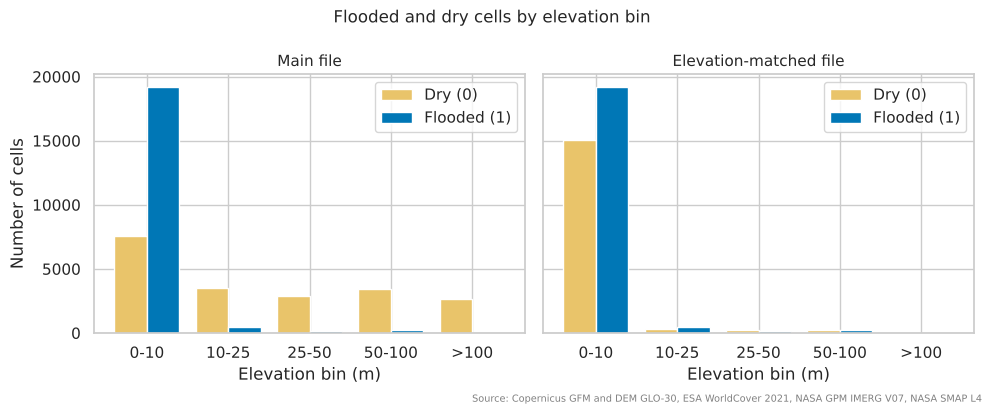

label        0      1
elev_bin             
0-10      7570  19222
10-25     3492    432
25-50     2874    154
50-100    3423    219
>100      2668      0


In [8]:
order = ['0-10', '10-25', '25-50', '50-100', '>100']
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
bins = {}
for ax, (name, d) in zip(axes, [('Main file', main), ('Elevation-matched file', matched)]):
    counts = d.groupby(['elev_bin', 'label']).size().unstack(fill_value=0).reindex(order).fillna(0)
    counts.plot.bar(ax=ax, color=[SAND, BLUE], rot=0, width=0.8)
    ax.set_title(name)
    ax.set_xlabel('Elevation bin (m)')
    ax.set_ylabel('Number of cells')
    ax.legend(['Dry (0)', 'Flooded (1)'])
    bins[name] = counts
save(fig, '03_elevation_bins.png', 'Flooded and dry cells by elevation bin')
print(bins['Main file'])

**Observation:** most flooded cells are in the 0-10 m bin and none are above 100 m. The matched file adds dry cells in the same low bin, but there are still very few cells in the higher bins, so a model has little to learn about higher areas.

### 5.3 Terrain features

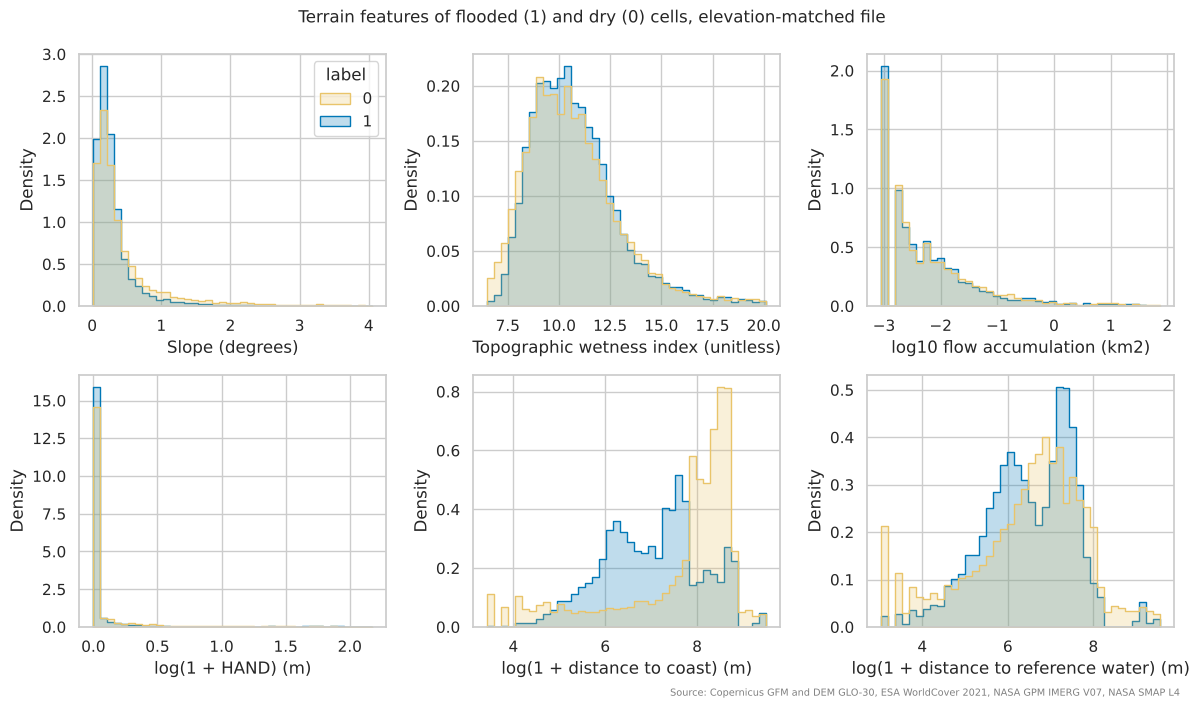

               slope_deg     twi  flowacc_km2  hand_m  dist_to_coast_m  \
file    label                                                            
main    0          0.918   8.433        0.002   1.476          7020.00   
        1          0.223  10.439        0.004   0.000          1233.29   
matched 0          0.270  10.309        0.004   0.000          3360.13   
        1          0.223  10.439        0.004   0.000          1233.29   

               dist_to_ref_water_m  
file    label                       
main    0                 5135.540  
        1                  694.622  
matched 0                  792.465  
        1                  694.622  


In [9]:
# Using the matched file, because elevation does not dominate there
plots = [('slope_deg', 'Slope (degrees)'), ('twi', 'Topographic wetness index (unitless)'),
         ('flowacc_log10', 'log10 flow accumulation (km2)'), ('hand_log1p', 'log(1 + HAND) (m)'),
         ('dist_coast_log1p', 'log(1 + distance to coast) (m)'), ('dist_refwater_log1p', 'log(1 + distance to reference water) (m)')]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (col, label) in zip(axes.ravel(), plots):
    low, high = matched[col].quantile([0.005, 0.995])
    sns.histplot(data=matched, x=col, hue='label', palette=LABEL_COLORS, stat='density', common_norm=False,
                 element='step', bins=40, binrange=(low, high), ax=ax, legend=(col == 'slope_deg'))
    ax.set_xlabel(label)
    ax.set_ylabel('Density')
save(fig, '04_terrain_features.png', 'Terrain features of flooded (1) and dry (0) cells, elevation-matched file')

cols = ['slope_deg', 'twi', 'flowacc_km2', 'hand_m', 'dist_to_coast_m', 'dist_to_ref_water_m']
medians = pd.concat({'main': main.groupby('label')[cols].median(), 'matched': matched.groupby('label')[cols].median()}, names=['file'])
medians.round(3).to_csv(OUT / 'feature_medians_by_label.csv')
print(medians.round(3))

**Observation:** in the matched file, slope, TWI, flow accumulation and HAND are similar for flooded and dry cells. The clearest difference is the distance to the coast: flooded cells are much closer to it. This is a statistical pattern, not proof of a cause. The distance to the coast may also reflect where the radar could detect water.

### 5.4 Land cover

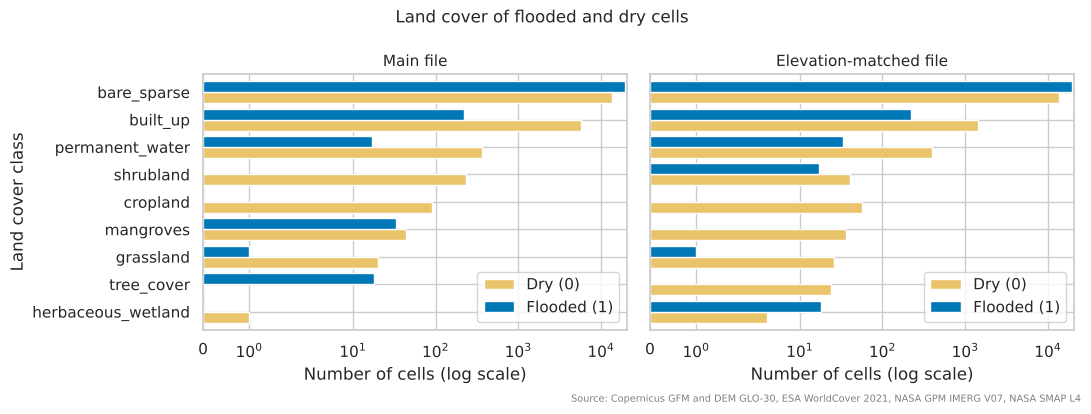

label                        0      1  flooded_pct
file    landcover_group                           
main    bare_sparse      13604  19739         59.2
        built_up          5670    219          3.7
        vegetation         708     18          2.5
        water_wetland       45     51         53.1
matched bare_sparse      13802  19739         58.9
        built_up          1436    219         13.2
        vegetation         146     18         11.0
        water_wetland      433     51         10.5


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, d) in zip(axes, [('Main file', main), ('Elevation-matched file', matched)]):
    counts = d.groupby(['landcover_name', 'label']).size().unstack(fill_value=0)
    counts = counts.loc[counts.sum(axis=1).sort_values().index]
    counts.plot.barh(ax=ax, color=[SAND, BLUE], width=0.8)
    ax.set_xscale('symlog')
    ax.set_title(name)
    ax.set_xlabel('Number of cells (log scale)')
    ax.set_ylabel('Land cover class')
    ax.legend(['Dry (0)', 'Flooded (1)'])
save(fig, '05_land_cover.png', 'Land cover of flooded and dry cells')

landcover = pd.concat({'main': main.groupby(['landcover_group', 'label']).size().unstack(fill_value=0),
                       'matched': matched.groupby(['landcover_group', 'label']).size().unstack(fill_value=0)}, names=['file'])
landcover['flooded_pct'] = (100 * landcover[1] / (landcover[0] + landcover[1])).round(1)
landcover.to_csv(OUT / 'landcover_by_label.csv')
print(landcover)

**Observation:** almost all flooded cells are bare or sparse land, and built-up areas are rare among flooded cells. This does not mean the city is safe: radar cannot see water between buildings, so most labels come from open land and the coast. A model trained on this data learns where flooding was *detected* more than where it actually happened.

### 5.5 Rainfall and soil moisture

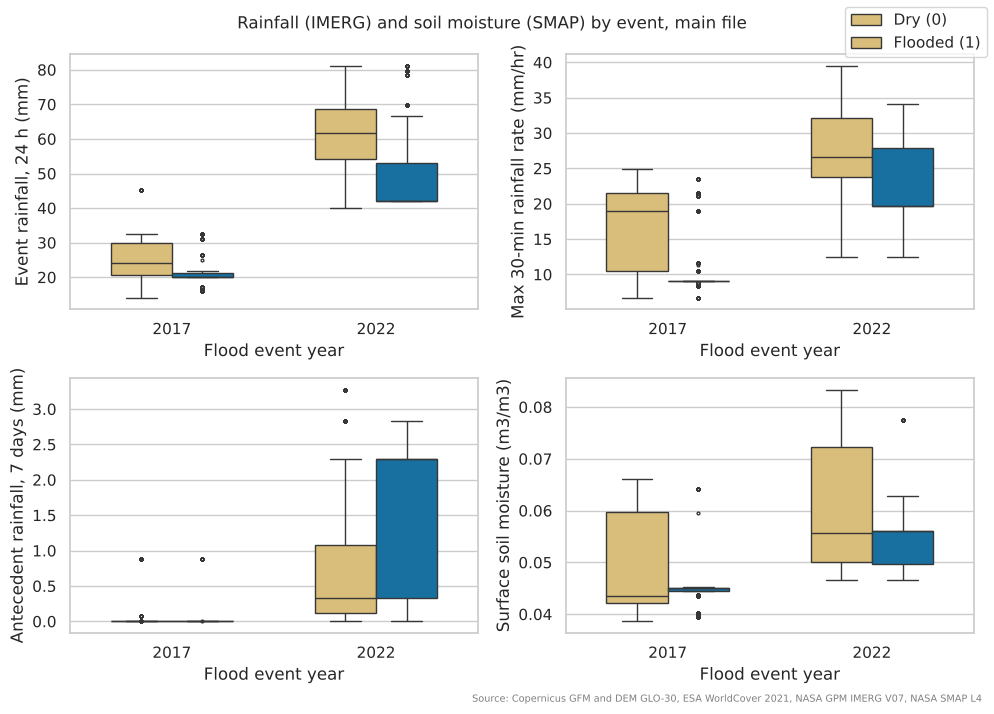

            rain_event_24h_mm  rain_event_max30_mmhr  rain_antecedent_7d_mm  \
year label                                                                    
2017 0                 24.145                  18.97                   0.00   
     1                 20.000                   9.13                   0.00   
2022 0                 61.695                  26.59                   0.33   
     1                 42.025                  19.61                   2.30   

            sm_surface_m3m3  sm_rootzone_m3m3  
year label                                     
2017 0                0.044             0.049  
     1                0.045             0.047  
2022 0                0.056             0.050  
     1                0.056             0.048  

Distinct values per event:
      rain_event_24h_mm  rain_event_max30_mmhr  rain_antecedent_7d_mm  \
year                                                                    
2017                 24                     24                 

In [11]:
variables = [('rain_event_24h_mm', 'Event rainfall, 24 h (mm)'), ('rain_event_max30_mmhr', 'Max 30-min rainfall rate (mm/hr)'),
             ('rain_antecedent_7d_mm', 'Antecedent rainfall, 7 days (mm)'), ('sm_surface_m3m3', 'Surface soil moisture (m3/m3)')]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (col, label) in zip(axes.ravel(), variables):
    sns.boxplot(data=main, x='year', y=col, hue='label', palette=LABEL_COLORS, ax=ax, width=0.6, fliersize=2)
    ax.set_xlabel('Flood event year')
    ax.set_ylabel(label)
    ax.legend_.remove()
fig.legend(['Dry (0)', 'Flooded (1)'], loc='upper right')
save(fig, '06_rainfall_soil_moisture.png', 'Rainfall (IMERG) and soil moisture (SMAP) by event, main file')

conditions = main.groupby(['year', 'label'])[[v for v, _ in variables] + ['sm_rootzone_m3m3']].median().round(3)
conditions.to_csv(OUT / 'event_conditions_by_label.csv')
print(conditions)
print()
print('Distinct values per event:')
print(main.groupby('year')[['rain_event_24h_mm', 'rain_event_max30_mmhr', 'rain_antecedent_7d_mm', 'sm_surface_m3m3']].nunique())
same = (main.rain_upstream_event_mm.round(3) == main.rain_event_24h_mm.round(3)).groupby(main.year).mean().round(3)
print('\nShare of rows where upstream rainfall equals 24 h rainfall:')
print(same)

**Observation:** the 2022 event has much more rainfall than 2017 according to IMERG. Within each event (main file), the median 24 h rainfall and the maximum 30-min rate are *lower* for flooded cells, which is the opposite of what we would expect physically. A likely explanation is that IMERG is coarse (about 11 km, only 24 distinct values per event), so it works as a rough location indicator and not as a real local effect. This is an interpretation, not a proof. Also, `rain_upstream_event_mm` is almost identical to `rain_event_24h_mm`, so we will not use it.

### 5.6 Maps

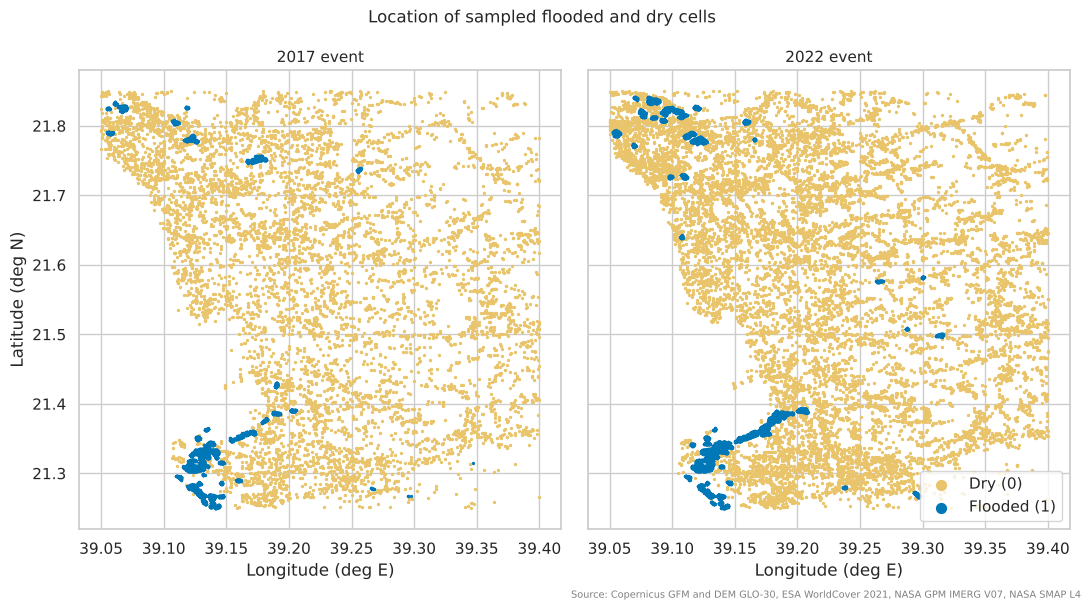

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharex=True, sharey=True)
for ax, year in zip(axes, [2017, 2022]):
    d = main[main.year == year]
    ax.scatter(d.lon[d.label == 0], d.lat[d.label == 0], s=2, color=SAND, label='Dry (0)')
    ax.scatter(d.lon[d.label == 1], d.lat[d.label == 1], s=2, color=BLUE, label='Flooded (1)')
    ax.set_title(f'{year} event')
    ax.set_xlabel('Longitude (deg E)')
axes[0].set_ylabel('Latitude (deg N)')
axes[1].legend(markerscale=5, loc='lower right')
save(fig, '07_map_flood_labels.png', 'Location of sampled flooded and dry cells')

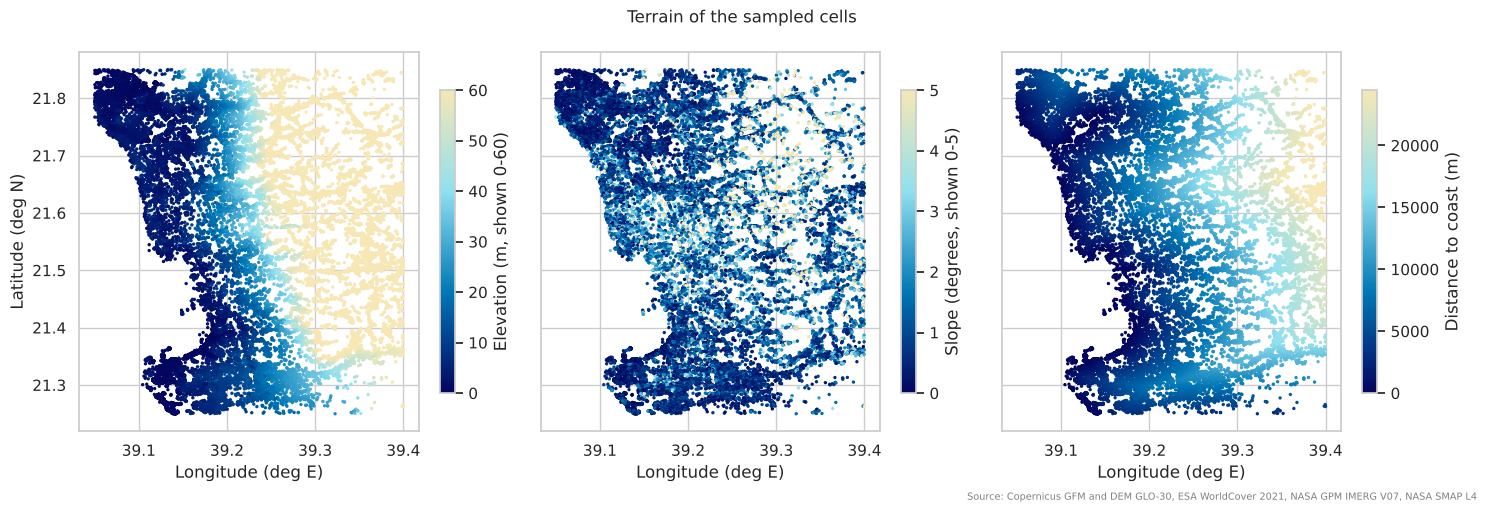

In [13]:
cells = main.drop_duplicates('cell_id')   # each cell once
maps = [('elevation_m', 'Elevation (m, shown 0-60)', 0, 60), ('slope_deg', 'Slope (degrees, shown 0-5)', 0, 5),
        ('dist_to_coast_m', 'Distance to coast (m)', 0, cells.dist_to_coast_m.quantile(0.99))]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, (col, label, low, high) in zip(axes, maps):
    points = ax.scatter(cells.lon, cells.lat, c=cells[col], s=2, cmap=water_cmap.reversed(), vmin=low, vmax=high)
    fig.colorbar(points, ax=ax, shrink=0.8, label=label)
    ax.set_xlabel('Longitude (deg E)')
axes[0].set_ylabel('Latitude (deg N)')
save(fig, '08_map_terrain.png', 'Terrain of the sampled cells')

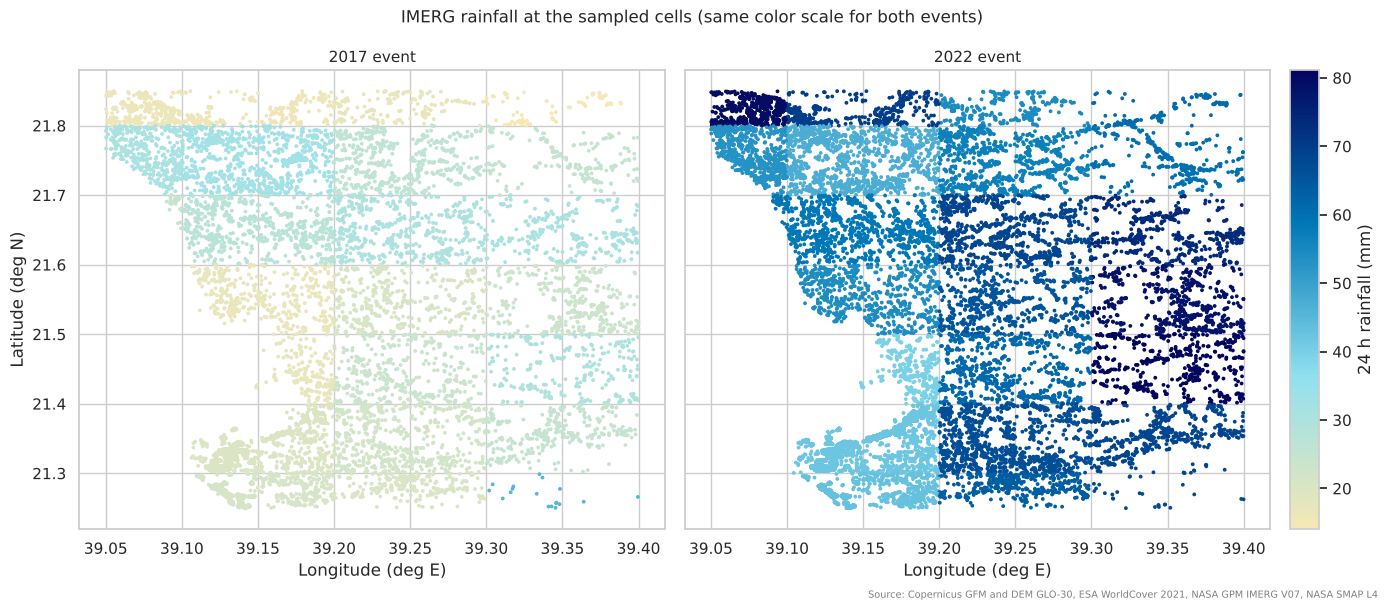

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 1, 0.05]})
for ax, year in zip(axes[:2], [2017, 2022]):
    d = main[main.year == year]
    points = ax.scatter(d.lon, d.lat, c=d.rain_event_24h_mm, s=3, cmap=water_cmap,
                        vmin=main.rain_event_24h_mm.min(), vmax=main.rain_event_24h_mm.max())
    ax.set_title(f'{year} event')
    ax.set_xlabel('Longitude (deg E)')
axes[0].set_ylabel('Latitude (deg N)')
axes[1].set_yticklabels([])
fig.colorbar(points, cax=axes[2], label='24 h rainfall (mm)')
save(fig, '09_map_rainfall.png', 'IMERG rainfall at the sampled cells (same color scale for both events)')

**Observation:** the rainfall appears as large blocks (about 11 km), while each cell is only 30 m. Neighboring cells therefore get the same rainfall value, and rainfall cannot explain differences between them. The label map shows that flooded cells are mostly along the coast.

### 5.7 Spatial concentration

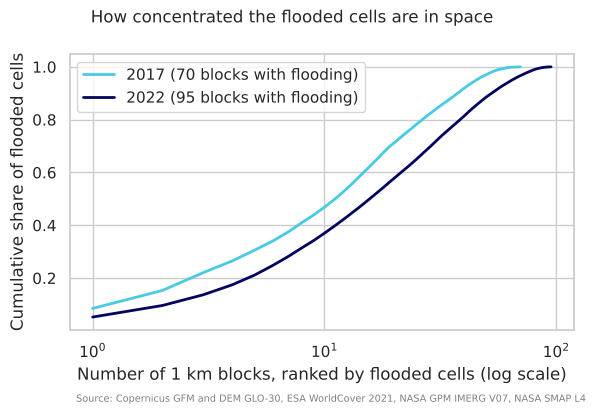

2017: top 10 blocks (1 km) hold 46.8% of flooded cells
2022: top 10 blocks (1 km) hold 37.0% of flooded cells
10 km blocks: 34 in total, 16 contain flooded cells, top 5 hold 92.7% of flooded cells


In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
concentration = {}
for year, color in [(2017, AQUA), (2022, NAVY)]:
    per_block = main[(main.year == year) & (main.label == 1)].groupby('block_id').size().sort_values(ascending=False)
    share = per_block.cumsum() / per_block.sum()
    concentration[year] = share
    ax.plot(np.arange(1, len(share) + 1), share.values, color=color, lw=2, label=f'{year} ({len(per_block)} blocks with flooding)')
ax.set_xscale('log')
ax.set_xlabel('Number of 1 km blocks, ranked by flooded cells (log scale)')
ax.set_ylabel('Cumulative share of flooded cells')
ax.legend()
save(fig, '10_spatial_concentration.png', 'How concentrated the flooded cells are in space')

for year, share in concentration.items():
    print(f'{year}: top 10 blocks (1 km) hold {share.iloc[:10].iloc[-1]:.1%} of flooded cells')
flooded_10km = main[main.label == 1].groupby('block_10km').size().sort_values(ascending=False)
print(f'10 km blocks: {main.block_10km.nunique()} in total, {len(flooded_10km)} contain flooded cells, '
      f'top 5 hold {flooded_10km.head(5).sum() / flooded_10km.sum():.1%} of flooded cells')

**Observation:** flooded cells are concentrated in a small number of places. This matters for validation: with large spatial blocks, the folds will be unbalanced and the results will vary a lot between folds, so we should report results per fold and not only the average.

### 5.8 Do the same places flood in both events?

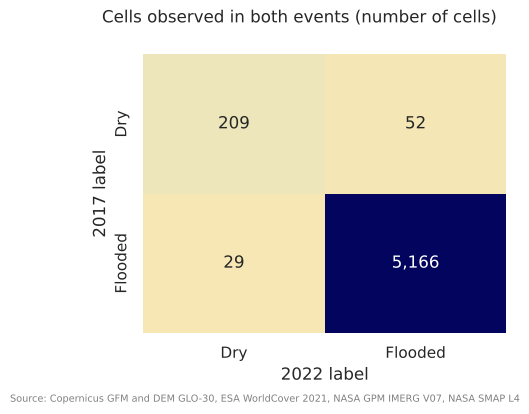

Cells in both events: 5456 | flooded in both: 5166


In [16]:
both = main.pivot_table(index='cell_id', columns='year', values='label', aggfunc='first').dropna()
table = pd.crosstab(both[2017], both[2022]).rename(index={0: 'Dry', 1: 'Flooded'}, columns={0: 'Dry', 1: 'Flooded'})
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(table, annot=True, fmt=',d', cmap=water_cmap, cbar=False, ax=ax)
ax.set_xlabel('2022 label')
ax.set_ylabel('2017 label')
save(fig, '11_event_overlap.png', 'Cells observed in both events (number of cells)')
print('Cells in both events:', len(both), '| flooded in both:', int(((both[2017] == 1) & (both[2022] == 1)).sum()))

**Observation:** many cells appear in both events, and most of the flooded ones flooded in both. This supports the quality of the labels (two independent radar images give the same places). It also means a random train/test split would put the same cell in both sets and leak information, so the data should be split by location or by event.

### 5.9 Correlations

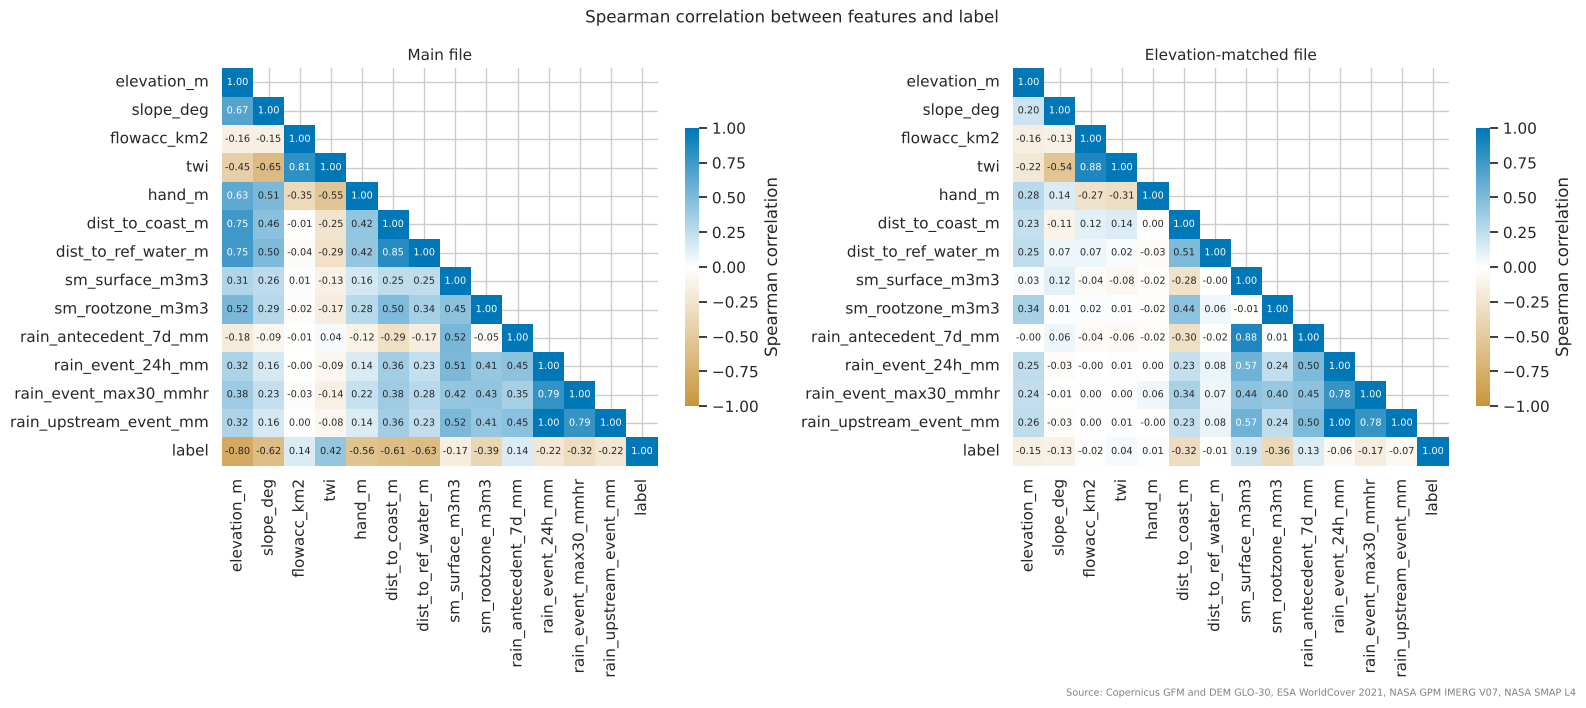

Most correlated feature pairs (main file):
rain_upstream_event_mm  rain_event_24h_mm        1.00
dist_to_ref_water_m     dist_to_coast_m          0.85
twi                     flowacc_km2              0.81
rain_event_max30_mmhr   rain_event_24h_mm        0.79
rain_upstream_event_mm  rain_event_max30_mmhr    0.79
dist_to_coast_m         elevation_m              0.75
dtype: float64


In [17]:
columns = ['elevation_m', 'slope_deg', 'flowacc_km2', 'twi', 'hand_m', 'dist_to_coast_m', 'dist_to_ref_water_m',
           'sm_surface_m3m3', 'sm_rootzone_m3m3', 'rain_antecedent_7d_mm', 'rain_event_24h_mm',
           'rain_event_max30_mmhr', 'rain_upstream_event_mm', 'label']
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, d) in zip(axes, [('Main file', main), ('Elevation-matched file', matched)]):
    corr = d[columns].corr(method='spearman')
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), 1), cmap=div_cmap, center=0, vmin=-1, vmax=1,
                annot=True, fmt='.2f', annot_kws={'fontsize': 7}, cbar_kws={'label': 'Spearman correlation', 'shrink': 0.7}, ax=ax)
    ax.set_title(name)
    corr.to_csv(OUT / f"correlation_{'main' if d is main else 'matched'}.csv")
save(fig, '12_correlation.png', 'Spearman correlation between features and label')

corr = main[columns[:-1]].corr(method='spearman')
pairs = corr.where(np.tril(np.ones(corr.shape, dtype=bool), -1)).stack().abs().sort_values(ascending=False)
print('Most correlated feature pairs (main file):')
print(pairs.head(6).round(2))

**Observation:** the strongest correlations are between distance to coast and distance to reference water (about 0.85), TWI and flow accumulation (about 0.81), elevation and distance to coast (about 0.75), and between the rainfall columns. Tree-based models are not affected much by this, but Logistic Regression needs regularization. A correlation with the label is not evidence of a cause.

### 5.10 Which single features separate the classes?

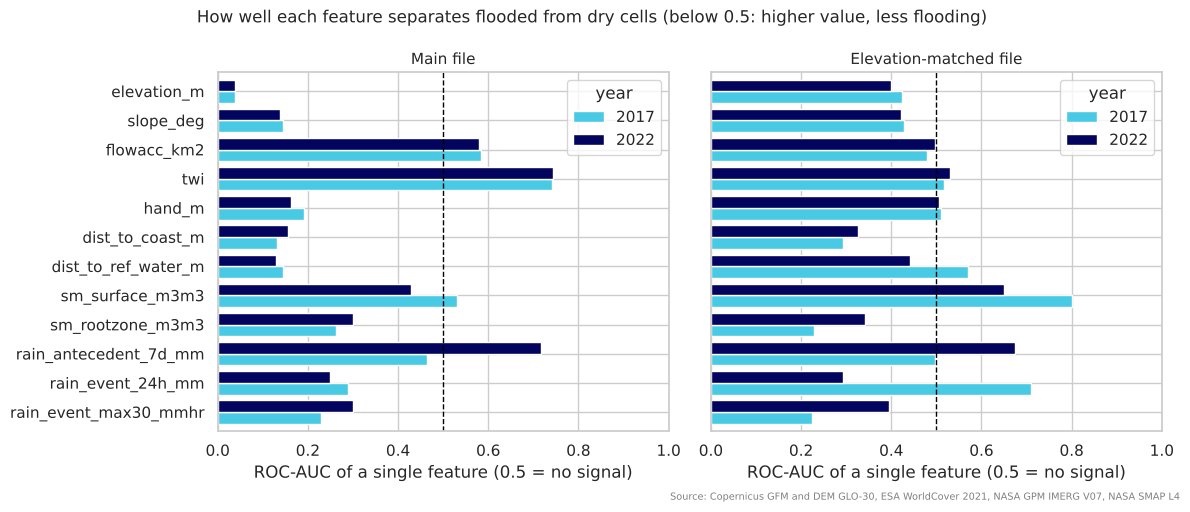

file                   main       matched      
year                   2017  2022    2017  2022
feature                                        
dist_to_coast_m        0.13  0.16    0.29  0.33
dist_to_ref_water_m    0.14  0.13    0.57  0.44
elevation_m            0.04  0.04    0.42  0.40
flowacc_km2            0.58  0.58    0.48  0.50
hand_m                 0.19  0.16    0.51  0.51
rain_antecedent_7d_mm  0.46  0.72    0.50  0.68
rain_event_24h_mm      0.29  0.25    0.71  0.29
rain_event_max30_mmhr  0.23  0.30    0.22  0.40
slope_deg              0.14  0.14    0.43  0.42
sm_rootzone_m3m3       0.26  0.30    0.23  0.34
sm_surface_m3m3        0.53  0.43    0.80  0.65
twi                    0.74  0.74    0.52  0.53


In [18]:
# ROC-AUC of each feature alone, computed separately inside each event (no model is trained)
features = ['elevation_m', 'slope_deg', 'flowacc_km2', 'twi', 'hand_m', 'dist_to_coast_m', 'dist_to_ref_water_m',
            'sm_surface_m3m3', 'sm_rootzone_m3m3', 'rain_antecedent_7d_mm', 'rain_event_24h_mm', 'rain_event_max30_mmhr']
rows = []
for name, d in [('main', main), ('matched', matched)]:
    for year in [2017, 2022]:
        part = d[d.year == year]
        for f in features:
            x = part[[f, 'label']].dropna()
            rows.append({'file': name, 'year': year, 'feature': f, 'auc': roc_auc_score(x.label, x[f])})
auc = pd.DataFrame(rows)
auc.to_csv(OUT / 'univariate_auc.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, name in zip(axes, ['main', 'matched']):
    table = auc[auc.file == name].pivot(index='feature', columns='year', values='auc').loc[features[::-1]]
    table.plot.barh(ax=ax, color=[AQUA, NAVY], width=0.8)
    ax.axvline(0.5, color='black', lw=1, ls='--')
    ax.set_xlim(0, 1)
    ax.set_title('Main file' if name == 'main' else 'Elevation-matched file')
    ax.set_xlabel('ROC-AUC of a single feature (0.5 = no signal)')
    ax.set_ylabel('')
save(fig, '13_single_feature_auc.png', 'How well each feature separates flooded from dry cells (below 0.5: higher value, less flooding)')
print(auc.pivot_table(index='feature', columns=['file', 'year'], values='auc').round(2))

**Observation:** in the main file, elevation alone separates the classes very well (AUC about 0.04, i.e. strongly inverse), together with HAND and distance to the coast. In the matched file, elevation drops to about 0.4 and distance to the coast stays the strongest signal (about 0.3). The rainfall and soil moisture features change direction between the two events (for example 24 h rainfall in the matched file: about 0.71 in 2017 and 0.29 in 2022), so they are unstable and probably act as location indicators because of their coarse resolution.

## 6. Outliers
We use the IQR rule (1.5 x IQR) only to describe how many extreme values there are. We decided **not to remove or clip them**, because they are real physical values (high ground, long drainage paths, areas far from the coast) and not measurement errors. Removing them would delete the high areas completely. For the very skewed columns we use log versions instead.

In [19]:
cols = ['elevation_m', 'slope_deg', 'flowacc_log10', 'twi', 'hand_log1p', 'dist_coast_log1p', 'dist_refwater_log1p']
rows = {}
for c in cols:
    x = main[c].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    k = 1.5 * (q3 - q1)
    rows[c] = {'below_pct': 100 * (x < q1 - k).mean(), 'above_pct': 100 * (x > q3 + k).mean(), 'max': x.max()}
outliers = pd.DataFrame(rows).T.round(2)
outliers.to_csv(OUT / 'outliers_iqr_main.csv')
print(outliers)

                     below_pct  above_pct     max
elevation_m               0.00      14.94  249.33
slope_deg                 0.00       9.41   22.39
flowacc_log10             0.00       5.30    3.65
twi                       0.00       2.91   24.85
hand_log1p                0.00       1.38    3.55
dist_coast_log1p          0.05       0.00   10.25
dist_refwater_log1p       0.20       0.00   10.02


## 7. Preprocessing for modeling
The cleaned data and a few helper tools are saved for the modeling step:
- cleaned CSV files,
- feature sets (which columns to use in each experiment),
- `src/preprocessing.py` with an unfitted preprocessing pipeline (median imputation, scaling, one-hot encoding), a spatial cross-validation helper and an event-based split.

The imputer, scaler and encoder are **not** fitted here. They must be fitted on training data only (inside each fold) to avoid data leakage.

In [20]:
# Feature sets, built from the columns allowed in the data dictionary
terrain = ['elevation_m', 'slope_deg', 'flowacc_log10', 'twi', 'hand_log1p', 'dist_coast_log1p', 'dist_refwater_log1p', 'landcover_group']
soil = ['sm_surface_m3m3', 'sm_rootzone_m3m3']
rain = ['rain_antecedent_7d_mm', 'rain_event_24h_mm', 'rain_event_max30_mmhr']   # rain_upstream_event_mm left out (duplicate)

feature_sets = {'elevation_only': ['elevation_m'],
                'terrain': terrain,
                'terrain_soil': terrain + soil,
                'terrain_soil_rain': terrain + soil + rain}
info = {'feature_sets': feature_sets, 'target': 'label',
        'id_columns': ['cell_id', 'event_id', 'year', 'block_id', 'block_5km', 'block_10km', 'x', 'y', 'lon', 'lat']}
(PROC / 'feature_sets.json').write_text(json.dumps(info, indent=2))

main.to_csv(PROC / 'jeddah_flood_clean.csv', index=False)
matched.to_csv(PROC / 'jeddah_flood_elev_matched_clean.csv', index=False)
print(main.shape, matched.shape)

(40054, 32) (35844, 32)


In [21]:
preprocessing_code = '''
import json
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CATEGORICAL = ['landcover_group']


def load_feature_sets(path='data/processed/feature_sets.json'):
    return json.load(open(path))['feature_sets']


def make_preprocessor(features, scale=False):
    # unfitted preprocessing; use scale=True for Logistic Regression
    numeric = [c for c in features if c not in CATEGORICAL]
    categorical = [c for c in features if c in CATEGORICAL]
    numeric_steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        numeric_steps.append(('scale', StandardScaler()))
    parts = [('num', Pipeline(numeric_steps), numeric)]
    if categorical:
        parts.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical))
    return ColumnTransformer(parts)


def spatial_folds(df, group_col='block_5km', n_splits=5, seed=42):
    # cross-validation where each spatial block stays entirely in one fold
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return list(splitter.split(df, df['label'], groups=df[group_col]))


def event_split(df, train_year, test_year):
    # train on one flood event and test on the other
    return np.where(df.year == train_year)[0], np.where(df.year == test_year)[0]
'''
(ROOT / 'src/preprocessing.py').write_text(preprocessing_code.strip() + '\n')

1502

In [22]:
# Quick check that the tools work (this is not model training)
import sys
sys.path.insert(0, str(ROOT))
from src import preprocessing as prep

sets = prep.load_feature_sets()
folds = prep.spatial_folds(matched, 'block_5km', 5)
train_idx, test_idx = folds[0]
pre = prep.make_preprocessor(sets['terrain_soil_rain'], scale=True)
X_train = pre.fit_transform(matched.iloc[train_idx])      # fit on training data only
X_test = pre.transform(matched.iloc[test_idx])
print('Transformed shapes:', X_train.shape, X_test.shape, '| NaN values:', int(np.isnan(X_train).sum() + np.isnan(X_test).sum()))

check = pd.DataFrame([{'fold': i, 'test_cells': len(te), 'test_flooded': int(matched.label.iloc[te].sum()),
                       'flooded_share': round(matched.label.iloc[te].mean(), 2),
                       'blocks_shared_with_train': len(set(matched.block_5km.iloc[te]) & set(matched.block_5km.iloc[tr]))}
                      for i, (tr, te) in enumerate(folds)])
check.to_csv(OUT / 'spatial_folds_check.csv', index=False)
print(check.to_string(index=False))

Transformed shapes: (28152, 16) (7692, 16) | NaN values: 0


 fold  test_cells  test_flooded  flooded_share  blocks_shared_with_train
    0        7692          2303           0.30                         0
    1        6125          3606           0.59                         0
    2        9208          6728           0.73                         0
    3        6677          4165           0.62                         0
    4        6142          3225           0.53                         0


## 8. Summary of findings

In [23]:
years = main.groupby('year').label.agg(['count', 'sum'])
elev_main, elev_matched = main.groupby('label').elevation_m.median(), matched.groupby('label').elevation_m.median()
auc_main = auc[auc.file == 'main'].groupby('feature').auc.mean().round(2)
auc_matched = auc[auc.file == 'matched'].groupby('feature').auc.mean().round(2)
top10 = {y: s.iloc[:10].iloc[-1] for y, s in concentration.items()}
both_flooded = int(((both[2017] == 1) & (both[2022] == 1)).sum())

text = f'''# EDA Findings: Jeddah Flood Dataset

The dataset covers two flood events (21 Nov 2017 and 24 Nov 2022). All numbers below were computed in `notebooks/02_eda.ipynb`, and the findings describe these two events only.

## 1. Data
- Main file: {len(main):,} rows ({int(years.loc[2017, 'count']):,} in 2017 and {int(years.loc[2022, 'count']):,} in 2022). Elevation-matched file: {len(matched):,} rows.
- Share of flooded cells: {main.label.mean():.0%} (main) and {matched.label.mean():.0%} (matched). This comes from the sampling design and is not the real flood prevalence, so precision and PR-AUC will not reflect real-world performance.
- No duplicate rows and no physically impossible values.

## 2. Missing values
- `slope_deg` and `twi`: {int(main.slope_deg.isna().sum())} missing in the main file and {int(matched.slope_deg.isna().sum())} in the matched file (mostly dry cells). `hand_m`: {int(main.hand_m.isna().sum())} missing in the main file. All other model inputs are complete.
- Handling: median imputation inside the modeling pipeline (fitted on training data only). No "is missing" features, because they would leak the label.

## 3. Elevation
- Median elevation in the main file: dry {elev_main[0]:.1f} m, flooded {elev_main[1]:.2f} m. In the matched file: dry {elev_matched[0]:.2f} m, flooded {elev_matched[1]:.2f} m.
- Single-feature ROC-AUC of elevation (mean of the two events): {auc_main['elevation_m']} in the main file and {auc_matched['elevation_m']} in the matched file. Every model should be compared to an elevation-only baseline.

## 4. Land cover
- Flooded cells are almost all bare or sparse land. Built-up areas are rare among flooded cells because radar cannot see water between buildings. This is a limit of the labels and does not mean that cities are safe.

## 5. Rainfall and soil moisture
- IMERG rainfall has only about 24 distinct values per event (about 11 km resolution). In the main file, 24 h rainfall and the maximum 30-min rate are lower at flooded cells, and in the matched file the direction of the single-feature AUC changes between events. They probably act as location indicators (interpretation, not proof).
- `rain_upstream_event_mm` is almost identical to `rain_event_24h_mm` and is not used.
- Models should be tested with and without the rainfall features.

## 6. Spatial structure
- The top 10 blocks of 1 km hold {top10[2017]:.0%} (2017) and {top10[2022]:.0%} (2022) of flooded cells.
- {len(both):,} cells appear in both events and {both_flooded:,} of them were flooded in both. A random split would leak information, so we split by location (`block_5km`) or by event.
- Spatial folds are unbalanced (see `outputs/spatial_folds_check.csv`), so results should be reported per fold.

## 7. Outliers
- Extreme values (high ground, long flow paths, far from the coast) are real and were kept. Log versions of the skewed columns are included.

## 8. Notes for modeling
1. Use spatial cross-validation on `block_5km` and also test 2017 to 2022 and 2022 to 2017.
2. Evaluate on the elevation-matched file and report an elevation-only baseline next to every model.
3. Compare the feature sets `terrain`, `terrain_soil` and `terrain_soil_rain`.
4. Report ROC-AUC, recall, F1 and the confusion matrix, never accuracy alone.

## 9. Limitations
- Radar sees little water inside the city, so labels come mostly from open land and the coast.
- Labels come from images taken 4-5 days after the events, so they show remaining water and not the maximum flood extent.
- Land cover is from 2021 for both events. Correlation does not mean causation.
'''
(ROOT / 'docs/eda_findings.md').write_text(text)
print(text[:600])

# EDA Findings: Jeddah Flood Dataset

The dataset covers two flood events (21 Nov 2017 and 24 Nov 2022). All numbers below were computed in `notebooks/02_eda.ipynb`, and the findings describe these two events only.

## 1. Data
- Main file: 40,054 rows (15,092 in 2017 and 24,962 in 2022). Elevation-matched file: 35,844 rows.
- Share of flooded cells: 50% (main) and 56% (matched). This comes from the sampling design and is not the real flood prevalence, so precision and PR-AUC will not reflect real-world performance.
- No duplicate rows and no physically impossible values.

## 2. Missing values



---
# Part 2 - Machine Learning

In this part we train and compare models that predict if flood water stays in a 30 m cell after a storm.
This is a binary classification problem: `label = 1` means flood water was seen by Sentinel-1 after the storm, `label = 0` means the cell was seen dry.
We start from the cleaned files saved in section 7.

## 9. Setup for modeling

In [24]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             roc_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
MODELS = ROOT / 'models'
FIG.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(exist_ok=True)

# preprocessing function from the EDA step (median imputation + one-hot encoding)
sys.path.append(str(ROOT / 'src'))
from preprocessing import make_preprocessor

# same colors as the EDA notebook
BLUE, SAND, NAVY, GRAY = '#0077B6', '#E9C46A', '#03045E', '#9AA0A6'
sns.set_theme(style='whitegrid')

## 10. Load the cleaned data

In [25]:
def find_file(name):
    # the EDA notebook saves to data/processed, the shared zip has the files in data/
    for folder in [ROOT / 'data' / 'processed', ROOT / 'data']:
        if (folder / name).exists():
            return folder / name
    raise FileNotFoundError(name + ' not found, run 02_eda.ipynb first')

main = pd.read_csv(find_file('jeddah_flood_clean.csv'))
matched = pd.read_csv(find_file('jeddah_flood_elev_matched_clean.csv'))
datasets = {'main': main, 'matched': matched}

for name, df in datasets.items():
    print(name, df.shape, '- flooded share:', round(df.label.mean(), 2))

main (40054, 32) - flooded share: 0.5
matched (35844, 32) - flooded share: 0.56


We have two files:
- **main**: the dry cells were sampled from all of Jeddah.
- **matched**: the dry cells have the same elevation as the flooded cells. This is the harder test.

From the EDA we know that elevation alone separates the classes very well in the main file. So we always compare our models with a simple elevation baseline. We also know the 50/50 balance comes from the sampling, so we don't use SMOTE and we don't look at accuracy only.

## 11. Features

In [26]:
feature_sets = json.load(open(find_file('feature_sets.json')))['feature_sets']

# extra test: terrain without the two distance features
feature_sets['terrain_no_coast'] = [f for f in feature_sets['terrain']
                                    if f not in ['dist_coast_log1p', 'dist_refwater_log1p']]

for name, cols in feature_sets.items():
    print(name, ':', cols)

elevation_only : ['elevation_m']
terrain : ['elevation_m', 'slope_deg', 'flowacc_log10', 'twi', 'hand_log1p', 'dist_coast_log1p', 'dist_refwater_log1p', 'landcover_group']
terrain_soil : ['elevation_m', 'slope_deg', 'flowacc_log10', 'twi', 'hand_log1p', 'dist_coast_log1p', 'dist_refwater_log1p', 'landcover_group', 'sm_surface_m3m3', 'sm_rootzone_m3m3']
terrain_soil_rain : ['elevation_m', 'slope_deg', 'flowacc_log10', 'twi', 'hand_log1p', 'dist_coast_log1p', 'dist_refwater_log1p', 'landcover_group', 'sm_surface_m3m3', 'sm_rootzone_m3m3', 'rain_antecedent_7d_mm', 'rain_event_24h_mm', 'rain_event_max30_mmhr']
terrain_no_coast : ['elevation_m', 'slope_deg', 'flowacc_log10', 'twi', 'hand_log1p', 'landcover_group']


The main feature set is `terrain` (elevation, slope, flow accumulation, TWI, HAND, distance to coast and to known water, land cover).
Soil moisture and rain are only tested as extra features, because the EDA showed they are very coarse (about 10 km) and change direction between the two events.

We make sure no ID, location or label column is used as a feature:

In [27]:
not_features = ['label', 'cell_id', 'event_id', 'year', 'x', 'y', 'lon', 'lat',
                'block_id', 'block_5km', 'block_10km', 'elev_bin', 'rain_upstream_event_mm']

for name, cols in feature_sets.items():
    assert not set(cols) & set(not_features), name
print('ok')

ok


## 12. How we split the data

A random split would be wrong here: cells next to each other are almost the same, and the same places flooded in 2017 and 2022. So we use three splits:

1. `spatial_cv`: 5 folds by 5 km blocks. A block is either in train or in test.
2. `event`: train on one storm, test on the other one (both directions).
3. `event_and_space`: train on one storm and test on the other storm **in blocks that were not used for training**. This is the strictest test and the one we use to compare models.

In [28]:
methods = ['spatial_cv', 'event', 'event_and_space']

# the 5 km folds are made once, so every model is tested on the same cells
folds = {}
for name, df in datasets.items():
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    folds[name] = list(cv.split(df, df.label, groups=df.block_5km))


def get_splits(name, method):
    df = datasets[name]
    year = df.year.values
    label = df.label.values

    if method == 'spatial_cv':
        for train_idx, test_idx in folds[name]:
            yield train_idx, test_idx

    if method == 'event':
        for a, b in [(2017, 2022), (2022, 2017)]:
            yield np.where(year == a)[0], np.where(year == b)[0]

    if method == 'event_and_space':
        for a, b in [(2017, 2022), (2022, 2017)]:
            for train_idx, test_idx in folds[name]:
                train_idx = train_idx[year[train_idx] == a]
                test_idx = test_idx[year[test_idx] == b]
                if len(np.unique(label[test_idx])) == 2:   # test fold needs both classes
                    yield train_idx, test_idx


# check: how many 5 km blocks are in both train and test?
for method in methods:
    shared = [len(set(main.block_5km.values[tr]) & set(main.block_5km.values[te]))
              for tr, te in get_splits('main', method)]
    print(f'{method:16s} splits: {len(shared):2d}   shared blocks: {shared}')

spatial_cv       splits:  5   shared blocks: [0, 0, 0, 0, 0]
event            splits:  2   shared blocks: [104, 104]
event_and_space  splits: 10   shared blocks: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


For the two spatial splits there are no shared blocks. The `event` split shares all places between the two storms, so its scores will be too optimistic.

## 13. Models

- **Elevation rule**: no training, "flooded if elevation < 10 m".
- **Logistic Regression on elevation only**: the baseline every model has to beat.
- **Logistic Regression**, **Random Forest** and **XGBoost** on the feature sets.

We keep the tree models small (big leaves, shallow trees) because there are only a few separate flooded areas, and we don't want the models to memorize places. The settings are fixed before testing and the threshold is 0.5.

In [29]:
def make_model(name, features):
    if name == 'logreg':
        clf = LogisticRegression(C=1.0, max_iter=2000)
    elif name == 'rf':
        clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features='sqrt',
                                     n_jobs=-1, random_state=42)
    elif name == 'xgb':
        clf = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                            colsample_bytree=0.8, min_child_weight=10, n_jobs=-1, random_state=42)
    # imputation and scaling are inside the pipeline, so they only learn from the training data
    return Pipeline([('prep', make_preprocessor(features, scale=(name == 'logreg'))), ('clf', clf)])


def train_and_predict(model_name, features, train, test):
    if model_name == 'elevation_rule':
        score = -test['elevation_m'].values              # lower ground = higher score
        pred = (test['elevation_m'] < 10).astype(int).values
        return score, pred
    model = make_model(model_name, features)
    model.fit(train[features], train['label'])
    score = model.predict_proba(test[features])[:, 1]
    return score, (score >= 0.5).astype(int)

## 14. Train and test all models
This takes around 5 minutes.

In [30]:
experiments = [('elevation_rule', 'elevation_only'), ('logreg', 'elevation_only')]
for model_name in ['logreg', 'rf', 'xgb']:
    for fs in ['terrain', 'terrain_no_coast', 'terrain_soil', 'terrain_soil_rain']:
        experiments.append((model_name, fs))

rows = []
predictions = {}

for name, df in datasets.items():
    for method in methods:
        for model_name, fs in experiments:
            features = feature_sets[fs]
            saved = []
            for i, (train_idx, test_idx) in enumerate(get_splits(name, method)):
                score, pred = train_and_predict(model_name, features, df.iloc[train_idx], df.iloc[test_idx])
                y = df.label.values[test_idx]
                rows.append({'data': name, 'method': method, 'model': model_name, 'features': fs, 'split': i,
                             'roc_auc': roc_auc_score(y, score),
                             'pr_auc': average_precision_score(y, score),
                             'precision': precision_score(y, pred, zero_division=0),
                             'recall': recall_score(y, pred),
                             'f1': f1_score(y, pred, zero_division=0)})
                saved.append(pd.DataFrame({'row': test_idx, 'y': y, 'score': score, 'pred': pred}))
            predictions[(name, method, model_name, fs)] = pd.concat(saved)
        print(name, method, 'done')

results = pd.DataFrame(rows)
results.to_csv(OUT / 'model_metrics_by_split.csv', index=False)

metrics = ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1']
summary = results.groupby(['data', 'method', 'model', 'features'], sort=False)[metrics].agg(['mean', 'std'])
summary.columns = [m + '_' + s for m, s in summary.columns]
summary = summary.round(3).reset_index()
summary.to_csv(OUT / 'model_metrics.csv', index=False)

main spatial_cv done


main event done


main event_and_space done


matched spatial_cv done


matched event done


matched event_and_space done


## 15. Results

Scores on the strict split (`event_and_space`), mean over the test folds:

In [31]:
strict = summary[summary.method == 'event_and_space']
table = strict[strict.features.isin(['elevation_only', 'terrain'])]
table[['data', 'model', 'features', 'roc_auc_mean', 'roc_auc_std', 'pr_auc_mean',
       'precision_mean', 'recall_mean', 'f1_mean']]

,data,model,features,roc_auc_mean,roc_auc_std,pr_auc_mean,precision_mean,recall_mean,f1_mean
28,main,elevation_rule,elevation_only,0.942,0.061,0.917,0.694,0.949,0.794
29,main,logreg,elevation_only,0.942,0.061,0.917,0.727,0.947,0.815
30,main,logreg,terrain,0.916,0.079,0.881,0.826,0.919,0.866
34,main,rf,terrain,0.936,0.067,0.920,0.928,0.837,0.873
38,main,xgb,terrain,0.926,0.083,0.910,0.924,0.785,0.841
70,matched,elevation_rule,elevation_only,0.502,0.216,0.547,0.539,0.947,0.668
71,matched,logreg,elevation_only,0.405,0.191,0.499,0.468,0.864,0.590
72,matched,logreg,terrain,0.668,0.113,0.659,0.629,0.762,0.675
76,matched,rf,terrain,0.671,0.144,0.684,0.661,0.529,0.560
80,matched,xgb,terrain,0.682,0.123,0.669,0.646,0.557,0.579


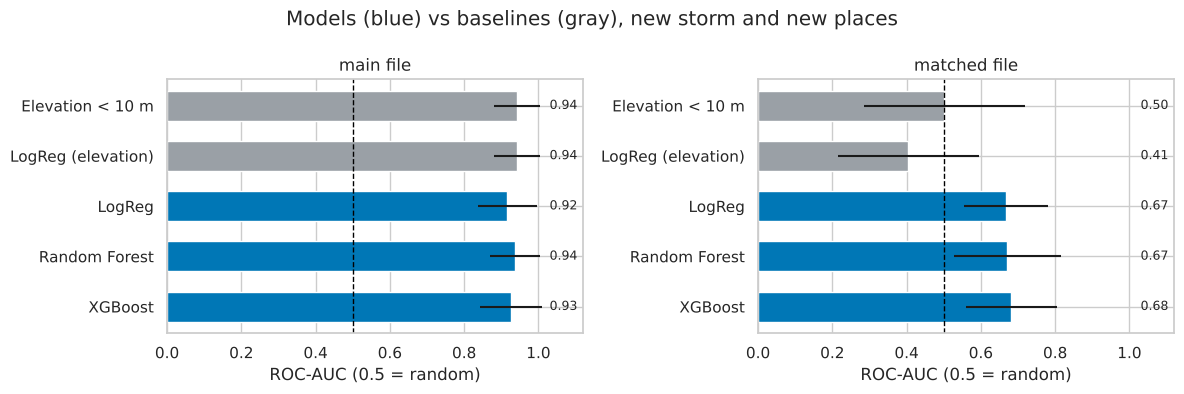

In [32]:
names = {'elevation_rule': 'Elevation < 10 m', 'logreg': 'LogReg', 'rf': 'Random Forest', 'xgb': 'XGBoost'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, name in zip(axes, datasets):
    t = table[table.data == name].iloc[::-1]
    labels = [names[m] + (' (elevation)' if (m == 'logreg' and f == 'elevation_only') else '')
              for m, f in zip(t.model, t.features)]
    colors = [GRAY if f == 'elevation_only' else BLUE for f in t.features]
    ax.barh(labels, t.roc_auc_mean, xerr=t.roc_auc_std, color=colors, height=0.6)
    for y, v in enumerate(t.roc_auc_mean):
        ax.text(1.03, y, f'{v:.2f}', va='center', fontsize=9)
    ax.axvline(0.5, ls='--', color='black', lw=1)
    ax.set_xlim(0, 1.12)
    ax.set_title(name + ' file')
    ax.set_xlabel('ROC-AUC (0.5 = random)')
fig.suptitle('Models (blue) vs baselines (gray), new storm and new places')
fig.tight_layout()
fig.savefig(FIG / 'ml_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

- In the **main** file the models get about 0.94, but the simple elevation rule gets the same. So here the models don't add anything: low ground near the sea is enough.
- In the **matched** file elevation doesn't help (around 0.5 or lower), but the models get about 0.67. So they learned something more than elevation, but the result is only moderate.
- The standard deviation is large because there are only a few flooded areas, and some folds are much harder than others.

### Does the split method change the score?

In [33]:
cfg = summary[summary.features.eq('terrain') | (summary.model.eq('logreg') & summary.features.eq('elevation_only'))]
cfg.pivot_table(index=['data', 'model', 'features'], columns='method', values='roc_auc_mean')[methods]

method                         spatial_cv  event  event_and_space
data    model  features                                          
main    logreg elevation_only       0.945  0.961            0.942
               terrain              0.925  0.936            0.916
        rf     terrain              0.951  0.963            0.936
        xgb    terrain              0.943  0.961            0.926
matched logreg elevation_only       0.406  0.589            0.405
               terrain              0.666  0.761            0.668
        rf     terrain              0.748  0.817            0.671
        xgb    terrain              0.751  0.801            0.682

The `event` split gives the highest scores because the same places are in train and test. This shows why a random or event-only split would give too good results.

### Which feature set is better?

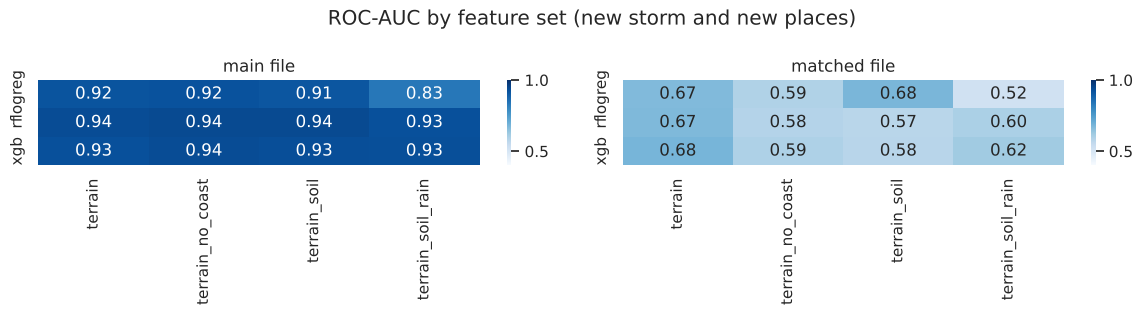

In [34]:
fs_order = ['terrain', 'terrain_no_coast', 'terrain_soil', 'terrain_soil_rain']
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, name in zip(axes, datasets):
    t = strict[(strict.data == name) & strict.model.isin(['logreg', 'rf', 'xgb'])]
    grid = t.pivot(index='model', columns='features', values='roc_auc_mean')[fs_order]
    sns.heatmap(grid, annot=True, fmt='.2f', cmap='Blues', vmin=0.4, vmax=1, ax=ax)
    ax.set_title(name + ' file')
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.suptitle('ROC-AUC by feature set (new storm and new places)')
fig.tight_layout()
fig.savefig(FIG / 'ml_feature_sets.png', dpi=200, bbox_inches='tight')
plt.show()

- Adding soil moisture and rain does not help on a new storm, it even makes the matched score worse. This matches the EDA: these features are too coarse.
- Without the distance to coast and distance to water features, the matched score drops a lot. So these two features carry most of the signal.

## 16. Choosing the model

In [35]:
choice = strict[strict.features == 'terrain'].pivot(index='model', columns='data', values='roc_auc_mean')
choice['average'] = choice.mean(axis=1)
choice

data,main,matched,average
model,,,
logreg,0.916,0.668,0.7920
rf,0.936,0.671,0.8035
xgb,0.926,0.682,0.8040


Random Forest and XGBoost are almost the same (difference below 0.01), and both are better than Logistic Regression. We choose **Random Forest with the terrain features**, because it is simpler to set up and was more stable on the main file.

In [36]:
best_model = 'rf'
best_fs = 'terrain'
features = feature_sets[best_fs]

## 17. Confusion matrix and ROC curve (Random Forest, strict split)

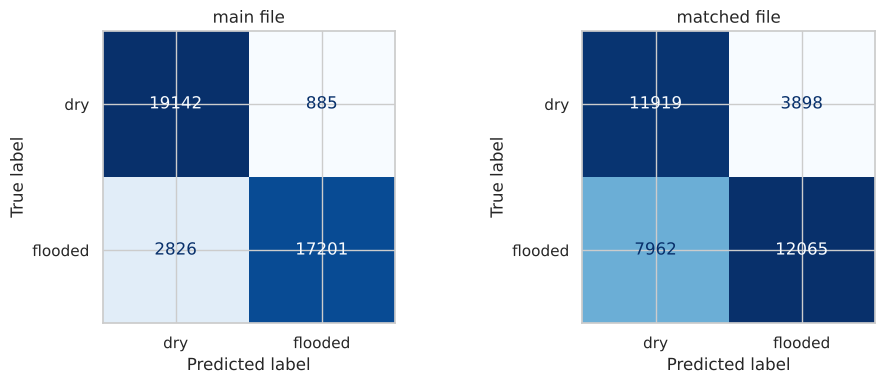

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, datasets):
    p = predictions[(name, 'event_and_space', best_model, best_fs)]
    ConfusionMatrixDisplay.from_predictions(p.y, p.pred, display_labels=['dry', 'flooded'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name + ' file')
fig.tight_layout()
fig.savefig(FIG / 'ml_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

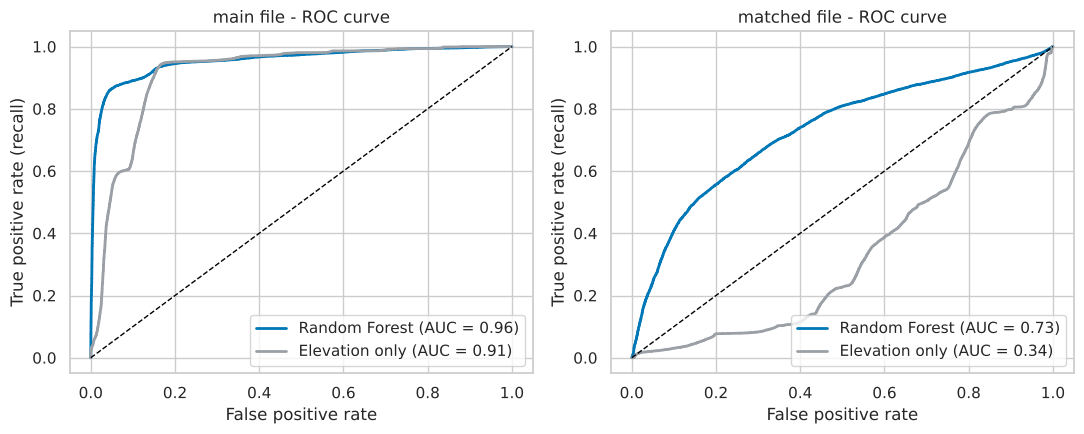

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for col, name in enumerate(datasets):
    for model_name, fs, color, label in [('rf', 'terrain', BLUE, 'Random Forest'),
                                         ('logreg', 'elevation_only', GRAY, 'Elevation only')]:
        p = predictions[(name, 'event_and_space', model_name, fs)]
        fpr, tpr, _ = roc_curve(p.y, p.score)
        auc = roc_auc_score(p.y, p.score)
        axes[col].plot(fpr, tpr, color=color, lw=2, label=f'{label} (AUC = {auc:.2f})')
    axes[col].plot([0, 1], [0, 1], ls='--', color='black', lw=1)
    axes[col].set_title(name + ' file - ROC curve')
    axes[col].set_xlabel('False positive rate')
    axes[col].set_ylabel('True positive rate (recall)')
    axes[col].legend(loc='lower right')
fig.tight_layout()
fig.savefig(FIG / 'ml_roc_curves.png', dpi=200, bbox_inches='tight')
plt.show()

In the matched file the model finds about half of the flooded cells (recall around 0.5). Keep in mind that in reality only 1 to 3% of cells flood, so the precision would be much lower than here, where it is 50/50.

## 18. Feature importance

We use permutation importance on the test folds: we shuffle one feature and see how much the ROC-AUC drops.

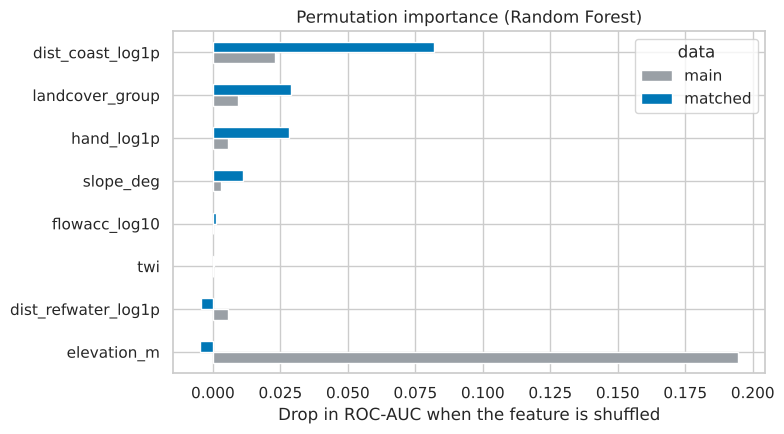

data,main,matched
feature,,
dist_coast_log1p,0.023,0.082
landcover_group,0.009,0.029
hand_log1p,0.006,0.028
slope_deg,0.003,0.011
flowacc_log10,-0.000,0.001
twi,0.000,0.000
dist_refwater_log1p,0.005,-0.005
elevation_m,0.195,-0.005


In [39]:
rows = []
for name, df in datasets.items():
    for train_idx, test_idx in get_splits(name, 'event_and_space'):
        model = make_model(best_model, features).fit(df.iloc[train_idx][features], df.label.iloc[train_idx])
        r = permutation_importance(model, df.iloc[test_idx][features], df.label.iloc[test_idx],
                                   scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1)
        for f, v in zip(features, r.importances_mean):
            rows.append({'data': name, 'feature': f, 'auc_drop': v})

importance = pd.DataFrame(rows).groupby(['data', 'feature']).auc_drop.mean().unstack(0)
importance = importance.sort_values('matched')

importance.plot.barh(figsize=(8, 4.5), color=[GRAY, BLUE])
plt.xlabel('Drop in ROC-AUC when the feature is shuffled')
plt.ylabel('')
plt.title('Permutation importance (Random Forest)')
plt.tight_layout()
plt.savefig(FIG / 'ml_feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()
importance.sort_values('matched', ascending=False).round(3)

- In the main file the model mostly uses **elevation**.
- In the matched file (where elevation can't help) it uses **distance to the coast**, then **land cover** and **HAND**.
- TWI and flow accumulation are almost not used.

## 19. Error analysis

Here we use the `spatial_cv` predictions, so every cell is predicted once by a model that did not see its block.

In [40]:
def error_rates(name, group_col):
    df = datasets[name]
    p = predictions[(name, 'spatial_cv', best_model, best_fs)].set_index('row').sort_index()
    df = df.assign(pred=p.pred.values)
    out = df.groupby(group_col).apply(lambda g: pd.Series({
        'cells': len(g),
        'flooded': g.label.sum(),
        'missed_floods': ((g.label == 1) & (g.pred == 0)).sum() / max(g.label.sum(), 1),
        'false_alarms': ((g.label == 0) & (g.pred == 1)).sum() / max((g.label == 0).sum(), 1)}))
    return out.round(2)

print('By land cover (main file)')
print(error_rates('main', 'landcover_group'))
print()
print('By elevation (main file)')
print(error_rates('main', 'elev_bin'))

By land cover (main file)
                   cells  flooded  missed_floods  false_alarms
landcover_group                                               
bare_sparse      33343.0  19739.0           0.09          0.07
built_up          5889.0    219.0           1.00          0.00
vegetation         726.0     18.0           0.94          0.00
water_wetland       96.0     51.0           0.65          0.33

By elevation (main file)
            cells  flooded  missed_floods  false_alarms
elev_bin                                               
0-10      26792.0  19222.0           0.06          0.14
10-25      3924.0    432.0           1.00          0.00
25-50      3028.0    154.0           1.00          0.00
50-100     3642.0    219.0           1.00          0.00
>100       2668.0      0.0           0.00          0.00


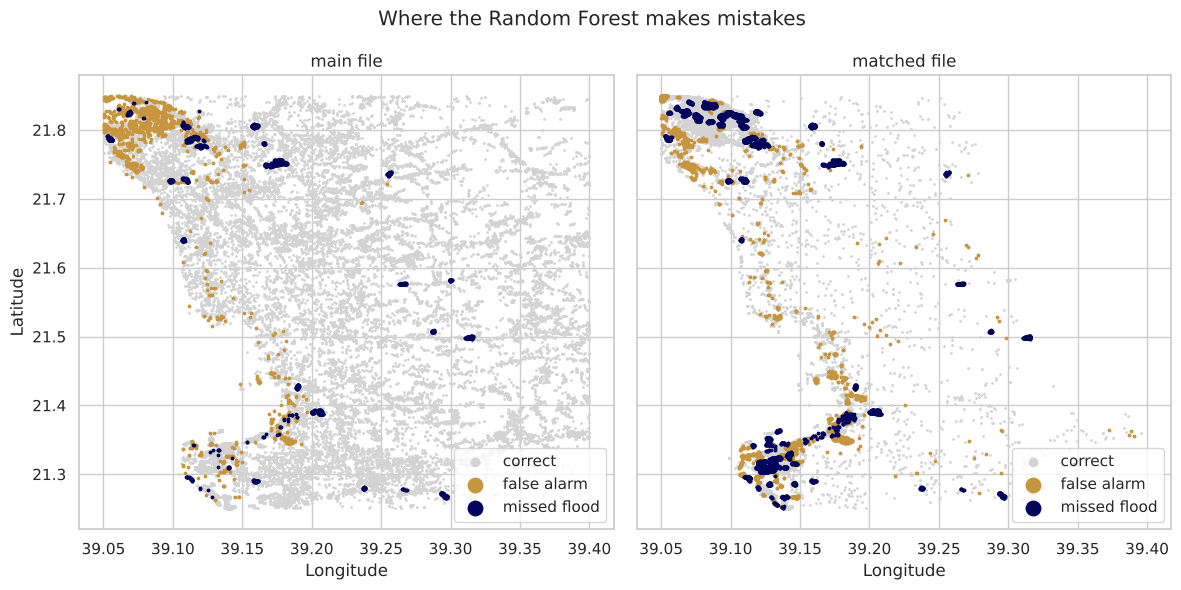

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, name in zip(axes, datasets):
    df = datasets[name]
    p = predictions[(name, 'spatial_cv', best_model, best_fs)].set_index('row').sort_index()
    missed = (df.label.values == 1) & (p.pred.values == 0)
    false_alarm = (df.label.values == 0) & (p.pred.values == 1)
    correct = ~missed & ~false_alarm
    ax.scatter(df.lon[correct], df.lat[correct], s=1, color='lightgray', label='correct')
    ax.scatter(df.lon[false_alarm], df.lat[false_alarm], s=3, color='#C9953C', label='false alarm')
    ax.scatter(df.lon[missed], df.lat[missed], s=3, color=NAVY, label='missed flood')
    ax.set_title(name + ' file')
    ax.set_xlabel('Longitude')
    ax.legend(markerscale=6, loc='lower right')
axes[0].set_ylabel('Latitude')
fig.suptitle('Where the Random Forest makes mistakes')
fig.tight_layout()
fig.savefig(FIG / 'ml_error_map.png', dpi=200, bbox_inches='tight')
plt.show()

- The model misses all flooded cells above 10 m and all flooded built-up cells. In the city this comes from the labels: the radar cannot see water between buildings.
- Most mistakes are on the southern coast (around 21.32°N) and north of Obhur (around 21.82°N), where the flooded and dry cells are very close to each other.

## 20. Train the final model and save it

The final Random Forest is trained on the whole main file (both storms), because its dry cells represent all of Jeddah. The scores above come from the test folds, here we just train once more on all the data with the same settings.

In [42]:
final_model = make_model(best_model, features)
final_model.fit(main[features], main['label'])

numeric = [f for f in features if f != 'landcover_group']
bundle = {
    'pipeline': final_model,
    'features': features,
    'threshold': 0.5,
    'training_range': {c: (float(main[c].min()), float(main[c].max())) for c in numeric},
    'info': 'Random Forest, terrain features, trained on the main file (2017 and 2022 storms). '
            'Score = relative flood susceptibility, not a probability and not water depth.',
}
joblib.dump(bundle, MODELS / 'flood_model.joblib')
print('saved', MODELS / 'flood_model.joblib')

saved models/flood_model.joblib


## 21. Conclusion

- We treated the problem as binary classification and tested the models on a new storm and new places, so the scores are not inflated by neighbouring cells.
- On the main file the models are not better than the rule "elevation below 10 m" (both about 0.94 ROC-AUC).
- On the matched file, where elevation does not help, the Random Forest gets about 0.67 ROC-AUC against 0.41-0.50 for the elevation baselines. The most useful features are distance to the coast, land cover and HAND.
- Rain and soil moisture did not help, because the satellite data is too coarse.
- The model can be used to compare the flood susceptibility of open areas in Jeddah. It cannot predict water depth, it doesn't work inside built-up areas, and it should not be used as a flood warning.

**Limitations:** only two storms with mostly the same flooded places, labels taken 4-5 days after the rain, no labels inside the city, elevation errors of a few metres near the coast, and land cover from 2021 for both storms.

**Next step:** test the model on a third storm (for example November 2026) when the satellite data is available.